# FPT — So dự báo với thực tế tháng 6–10/2026

## Tóm tắt
**104 phiên chung, 17 phương án, không train lại.** Notebook đọc các forecast đã lưu và cho xem giá, mức tăng/giảm, sai số từng tháng và đúng hướng. Tháng 10 chỉ có dữ liệu đến **29/10/2026**.

- LSTM: RMSE lợi suất **0,0168315**, baseline giữ nguyên giá **0,0167746**. Cùng đạt **80,77%** phiên sai số giá trong ±2%.
- Ridge refit theo tháng mô phỏng: RMSE **0,0167461**, nhỉnh hơn baseline ít; khoảng bất định vẫn chứa mức không cải thiện.
- Ridge train đến cuối 2025 + bias: đúng hướng **62,63%**, balanced **57,95%**; luôn đoán giảm trong tập này đã đạt **60,61%** hit.
- Đây là **chẩn đoán hồi cứu trên giai đoạn đã xem**, chưa chứng minh dự báo tương lai tốt hơn. Khác cutoff/source/features nên không cô lập riêng tác dụng của từng thuật toán.

**Xem nhanh:** biểu đồ đầu phần 3 đặt giá thực tế và nhiều model trên cùng một trục; phần 4 phóng to một tháng; phần 5–8 so metric và độ ổn định. File đã lưu sẵn bảng/biểu đồ, có thể đọc ngay không cần chạy.

## 1. Phạm vi và cách chấm

Tại cuối phiên **t**, dùng OHLCV đã quan sát đến t để dự báo close/return ở quan sát giao dịch kế tiếp. Lặp lại từng ngày, rồi gộp kết quả theo **tháng target**. Origin của ngày đầu tháng có thể nằm ở cuối tháng trước. Không phải dự báo cả 5 tháng từ đầu tháng 6 mà không cập nhật giá thật.

### Giả định và giới hạn
- Cùng origin/target pairs, cùng actual return và anchor giá Vietcap đã điều chỉnh cho mọi phương án; không trộn native price Yahoo với reference price.
- Biên độ ở đây là **close-to-close**, chưa phải High–Low trong phiên. Đường giá dự báo dùng **actual close của phiên origin** làm anchor nên nhìn sát đường giá chưa chứng minh ML có ích.
- Nhóm cố định chỉ học nhãn trước 2026. Nhóm bias/monthly/rolling sử dụng nhãn quá khứ đã chín theo quy tắc mô phỏng; không lấy nhãn tương lai hoặc model shadow đã train tới 29/10 để chấm ngược tháng 6–9.
- Tháng 9 có 18 cặp common, thiếu hai cặp không khớp giữa nguồn Yahoo và Vietcap. Giữ cùng mẫu cho mọi model, không tự thêm/bớt ngày để cải thiện điểm. Snapshot adjusted hiện tại chưa được chứng nhận point-in-time.
- 2026 đã được mở và dùng nghiên cứu. Không chọn champion bằng tháng đẹp; các biểu đồ không phải bằng chứng forecast đã phát live.

### Thiết lập để xem một tháng / model khác
Đổi `DETAIL_MONTH` và `DETAIL_MODEL` dưới đây rồi **Run all** để cập nhật phần phóng to. Biểu đồ chung ở phần 3 dùng `OVERLAY_MODELS`; đặt `OVERLAY_MONTH` thành một tháng nếu muốn xem các model chung trong tháng đó, hoặc `None` để xem toàn kỳ. Các metric tổng hợp vẫn giữ nguyên toàn bộ 104 phiên. Mọi model trong bảng danh mục đều có thể dùng để quan sát.

Cần `numpy`, `pandas`, `matplotlib`, `IPython`. Không cần TensorFlow, weights, API hoặc kết nối thị trường. Nếu chạy Colab, cần tải cả notebook và thư mục dữ liệu `reports/period_comparison/20261030T024048531444Z/`; đặt `DATA_DIR` tới thư mục đó nếu không chạy trong repo. Notebook không tự clone GitHub hoặc tải giá.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown

DETAIL_MONTH = '2026-10'       # 2026-06 / 07 / 08 / 09 / 10
DETAIL_MODEL = 'LSTM_serving'  # ví dụ: refit_2025_native_bias60
OVERLAY_MODELS = ['LSTM_serving', 'XGBoost_serving', 'Ridge_serving', 'refit_2025_native']
OVERLAY_MONTH = None          # None = toàn kỳ; hoặc '2026-10' để phóng to biểu đồ chung
DATA_DIR = None               # có thể đặt Path('/content/ten_thu_muc') trên Colab
STUDY = '20261030T024048531444Z'

if DATA_DIR is None:
    candidates = [p/'reports/period_comparison'/STUDY for p in [Path.cwd(), *Path.cwd().parents]]
    DATA_DIR = next((p for p in candidates if (p/'predictions.csv.gz').exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Cần thư mục dữ liệu của study. Đặt DATA_DIR tới nơi chứa predictions.csv.gz, summary.csv, monthly_metrics.csv, scope.json, verification.json.')
DATA_DIR = Path(DATA_DIR)
QA_DIR = Path.cwd()/'.cache/period-notebook-qa'
QA_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (12, 4.5), 'font.size': 11, 'axes.grid': True,
                     'grid.alpha': .18, 'figure.dpi': 110})

LABELS = {'LSTM_serving':'LSTM serving', 'XGBoost_serving':'XGBoost serving',
    'Ridge_serving':'Ridge serving', 'Ridge_research_new':'Ridge train ≤2023',
    'Ridge_research_old':'Ridge cũ alpha10', 'refit_2023_native':'Ridge native ≤2023',
    'refit_2025_native':'Ridge train ≤2025', 'refit_2025_native_bias60':'Ridge ≤2025 + bias',
    'monthly_refit_native':'Ridge monthly raw', 'monthly_refit_native_bias60':'Ridge monthly + bias',
    'frozen_2023_bias60':'Ridge ≤2023 + bias', 'RollingMean60':'Rolling mean 60',
    'TrainMean_2025':'Train mean ≤2025', 'TrainMean_serving':'Train mean serving',
    'TrainMean_research':'Train mean research', 'TrainMean_same_window':'Train mean cùng window',
    'Zero-Return':'Giữ nguyên giá'}
FOCUS = ['LSTM_serving','XGBoost_serving','Ridge_serving','Ridge_research_new',
         'refit_2025_native','refit_2025_native_bias60','monthly_refit_native',
         'monthly_refit_native_bias60','Zero-Return']
PRICE_MODELS = ['LSTM_serving', 'XGBoost_serving', 'refit_2025_native']
GROUP_LABELS = {'fixed_pre2026_training_labels':'Cố định · chỉ học nhãn trước 2026',
                'causal_time_order_simulation':'Cập nhật theo thời gian · mô phỏng'}

def show(name):
    plt.tight_layout()
    plt.savefig(QA_DIR/(name+'.png'), dpi=140, bbox_inches='tight')
    plt.show()

def readable(frame):
    return frame.style.format(precision=3, na_rep='—')

## 2. Dữ liệu và kiểm tra cùng mẫu
Kiểm tra hash của input đã chốt, tính lại metric từ từng forecast và đối soát với bảng lưu. Bảng dưới giữ rõ số ngày tăng/giảm/trung tính của từng tháng. Đây là kiểm tra dữ liệu của notebook; audit raw source, cutoff train và artifact đã được lưu trong hai study nguồn.

In [2]:
EXPECTED_SHA256 = {'predictions.csv.gz': '768f7a3981b576092373cc63a3c3cdc70ca71938b766409870bbe40263a7ecd6', 'summary.csv': '77276a51efce65302111d76a1f7d3a8d6b98529de522d5c92f1bec481300731e', 'monthly_metrics.csv': 'a93461d44d72e6ad3a85a39d00b7321c38d034c82e2e68f3545d8eed9a83b3b5', 'scope.json': '88a2337dc3f4e9264adcf11ecf394cb32608eedec2301e3cd28d6bde9a32aec6', 'verification.json': '8e2cebbfcd52cd4c626234238dda645f440f013428b9ac97b58d306eefdf8007'}

for filename, expected in EXPECTED_SHA256.items():
    actual = hashlib.sha256((DATA_DIR/filename).read_bytes()).hexdigest()
    assert actual == expected, f'Input đã thay đổi: {filename}. Cần kiểm tra lại study thay vì âm thầm đổi dữ liệu.'
scope = json.loads((DATA_DIR/'scope.json').read_text())
verification = json.loads((DATA_DIR/'verification.json').read_text())
predictions = pd.read_csv(DATA_DIR/'predictions.csv.gz', parse_dates=['Date','Target_Date_1d'])
summary = pd.read_csv(DATA_DIR/'summary.csv').set_index('strategy')
monthly = pd.read_csv(DATA_DIR/'monthly_metrics.csv')
predictions['target_month'] = predictions.Target_Date_1d.dt.strftime('%Y-%m')
predictions['actual_return_pct'] = 100*np.expm1(predictions.actual_log_return)
predictions['predicted_return_pct'] = 100*np.expm1(predictions.predicted_log_return)
predictions['price_error_pct'] = 100*np.expm1(predictions.predicted_log_return-predictions.actual_log_return)
baseline = predictions[predictions.strategy.eq('Zero-Return')].sort_values('Date').copy()
keys = list(zip(baseline.Date, baseline.Target_Date_1d))
assert len(keys) == 104 and len(summary) == 17
assert predictions.Target_Date_1d.gt(predictions.Date).all()
assert predictions.Target_Date_1d.between('2026-06-01','2026-10-29').all()
assert DETAIL_MODEL in summary.index, f'Model không có trong study: {DETAIL_MODEL}'
assert DETAIL_MONTH in baseline.target_month.unique(), 'Chọn tháng 2026-06 đến 2026-10.'
assert OVERLAY_MODELS and len(set(OVERLAY_MODELS)) == len(OVERLAY_MODELS)
assert set(OVERLAY_MODELS).issubset(summary.index), 'Kiểm tra tên model trong OVERLAY_MODELS.'
assert OVERLAY_MONTH is None or OVERLAY_MONTH in baseline.target_month.unique()
for model, group in predictions.groupby('strategy'):
    group = group.sort_values('Date')
    assert list(zip(group.Date, group.Target_Date_1d)) == keys
    y, q = group.actual_log_return.to_numpy(), group.predicted_log_return.to_numpy()
    assert np.allclose(y, baseline.actual_log_return)
    assert np.allclose(group.origin_close_adjusted, baseline.origin_close_adjusted)
    assert np.allclose(group.actual_close_adjusted, group.origin_close_adjusted*np.exp(y))
    assert np.allclose(group.predicted_close_adjusted, group.origin_close_adjusted*np.exp(q))
    row = summary.loc[model]
    assert np.isclose(np.sqrt(np.mean((q-y)**2)), row.rmse)
    assert np.isclose(np.mean(abs(group.predicted_close_adjusted-group.actual_close_adjusted)), row.price_mae_adjusted_vnd)
    assert np.isclose(100*np.mean(abs(np.expm1(q-y))<=.01), row.price_error_le_1pct_pct)
    assert np.isclose(100*np.mean(abs(np.expm1(q-y))<=.02), row.price_error_le_2pct_pct)
    if np.any(q != 0):
        assert np.isclose(100*np.mean(np.sign(q[y!=0])==np.sign(y[y!=0])), row.hit_rate_pct)
        balanced = 50*(np.mean(q[y>0]>0)+np.mean(q[y<0]<0))
        assert np.isclose(balanced, row.balanced_accuracy_pct)
    for month, part in group.groupby('target_month'):
        saved = monthly[(monthly.strategy==model)&(monthly.target_month==month)].iloc[0]
        assert len(part) == saved.n
        assert np.isclose(np.sqrt(np.mean((part.predicted_log_return-part.actual_log_return)**2)), saved.rmse)
counts = baseline.groupby('target_month').agg(N=('Date','size'),
    Tang=('actual_log_return',lambda x: int((x>0).sum())),
    Giam=('actual_log_return',lambda x: int((x<0).sum())),
    Khong_doi=('actual_log_return',lambda x: int((x==0).sum())))
display(counts.rename(columns={'Tang':'Tăng','Giam':'Giảm','Khong_doi':'Không đổi'}))
display(Markdown('**Đã đối soát:** 17 phương án × cùng 104 phiên, 85 nhóm tháng; không gọi fit/predict hoặc API thị trường.'))

,N,Tăng,Giảm,Không đổi
target_month,,,,
2026-06,22,9,12,1
2026-07,23,10,12,1
2026-08,20,10,10,0
2026-09,18,6,12,0
2026-10,21,4,14,3


**Đã đối soát:** 17 phương án × cùng 104 phiên, 85 nhóm tháng; không gọi fit/predict hoặc API thị trường.

### Danh mục model để đổi phần phóng to
Đây là đối chiếu các artifact/phương án có sẵn, chưa phải thử nghiệm giữ mọi điều kiện khác giống nhau để xếp hạng riêng thuật toán. Bias dùng tối đa 60 lỗi quá khứ, cần ít nhất 20 nhãn; monthly train theo cutoff tháng trước. Tên nhóm nói về **ngày nhãn training**, không khẳng định model đã được phát live trước năm 2026.

In [3]:
catalog = summary[['mode']].copy()
catalog.insert(0, 'Tên hiển thị', [LABELS.get(x,x) for x in catalog.index])
catalog['Nhóm'] = catalog.pop('mode').map(GROUP_LABELS)
display(catalog.rename_axis('DETAIL_MODEL'))

,Tên hiển thị,Nhóm
DETAIL_MODEL,,
LSTM_serving,LSTM serving,Cố định · chỉ học nhãn trước 2026
Ridge_research_new,Ridge train ≤2023,Cố định · chỉ học nhãn trước 2026
Ridge_research_old,Ridge cũ alpha10,Cố định · chỉ học nhãn trước 2026
Ridge_serving,Ridge serving,Cố định · chỉ học nhãn trước 2026
RollingMean60,Rolling mean 60,Cập nhật theo thời gian · mô phỏng
TrainMean_2025,Train mean ≤2025,Cố định · chỉ học nhãn trước 2026
TrainMean_research,Train mean research,Cố định · chỉ học nhãn trước 2026
TrainMean_same_window,Train mean cùng window,Cố định · chỉ học nhãn trước 2026
TrainMean_serving,Train mean serving,Cố định · chỉ học nhãn trước 2026


## 3. Giá dự báo và mức tăng/giảm thật
Mỗi panel dùng cùng actual target close và cùng ngày. Baseline là giữ giá origin. Giá đều ở mặt bằng **adjusted VND**, không phải giá thực thi lịch sử. Forecast được tính lại anchor mỗi ngày bằng giá origin thực tế, không ghép thành đường dự báo nhiều bước tự chạy.

### Giá thực tế và các model trên cùng một biểu đồ
**Đường đen đậm là giá thực tế**, các đường màu là giá dự đoán cho cùng target. Mặc định so LSTM, XGBoost, Ridge serving và Ridge refit đến cuối 2025. Đổi `OVERLAY_MODELS`/`OVERLAY_MONTH` ở đầu notebook để chọn model hoặc tháng. Các đường model có thể chồng lên nhau vì forecast gần nhau; không dịch đường hoặc đổi scale để tạo khác biệt giả.

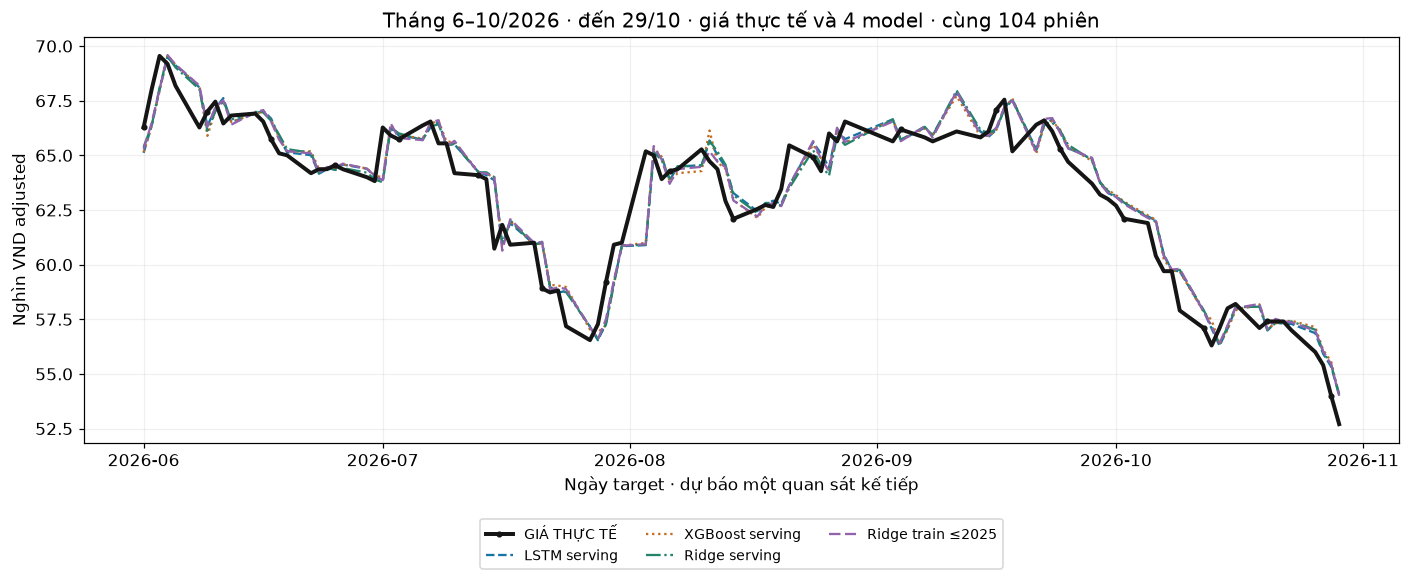

In [4]:
observed = baseline if OVERLAY_MONTH is None else baseline[baseline.target_month.eq(OVERLAY_MONTH)]
fig, ax = plt.subplots(figsize=(13, 5.5))
colors = ['#1674a5','#c56b1f','#23846a','#9163ac','#bd4a61','#677c32']
styles = ['--',':','-.',(0,(5,2))]
for i, model in enumerate(OVERLAY_MODELS):
    group = predictions[predictions.strategy.eq(model)]
    if OVERLAY_MONTH is not None:
        group = group[group.target_month.eq(OVERLAY_MONTH)]
    group = group.sort_values('Date')
    assert list(group.Target_Date_1d) == list(observed.Target_Date_1d)
    ax.plot(group.Target_Date_1d, group.predicted_close_adjusted/1000,
            color=colors[i%len(colors)], ls=styles[i%len(styles)], lw=1.5,
            label=LABELS.get(model,model))
ax.plot(observed.Target_Date_1d, observed.actual_close_adjusted/1000,
        color='#151515', lw=2.6, marker='o', markersize=3, markevery=max(1,len(observed)//15),
        label='GIÁ THỰC TẾ', zorder=10)
period = 'Tháng 6–10/2026 · đến 29/10' if OVERLAY_MONTH is None else OVERLAY_MONTH
ax.set_title(f'{period} · giá thực tế và {len(OVERLAY_MODELS)} model · cùng {len(observed)} phiên')
ax.set_ylabel('Nghìn VND adjusted'); ax.set_xlabel('Ngày target · dự báo một quan sát kế tiếp')
handles, labels = ax.get_legend_handles_labels()
ax.legend([handles[-1], *handles[:-1]], [labels[-1], *labels[:-1]],
          loc='upper center', bbox_to_anchor=(.5,-.17), ncol=3, fontsize=9)
show('00_actual_vs_all_models')

### Tách từng model để nhìn rõ hơn
Các panel dưới giữ cùng thang giá và thêm baseline giữ giá origin. Phần return tiếp theo giúp phân biệt độ chính xác dự báo với việc đường giá được anchor lại mỗi ngày.

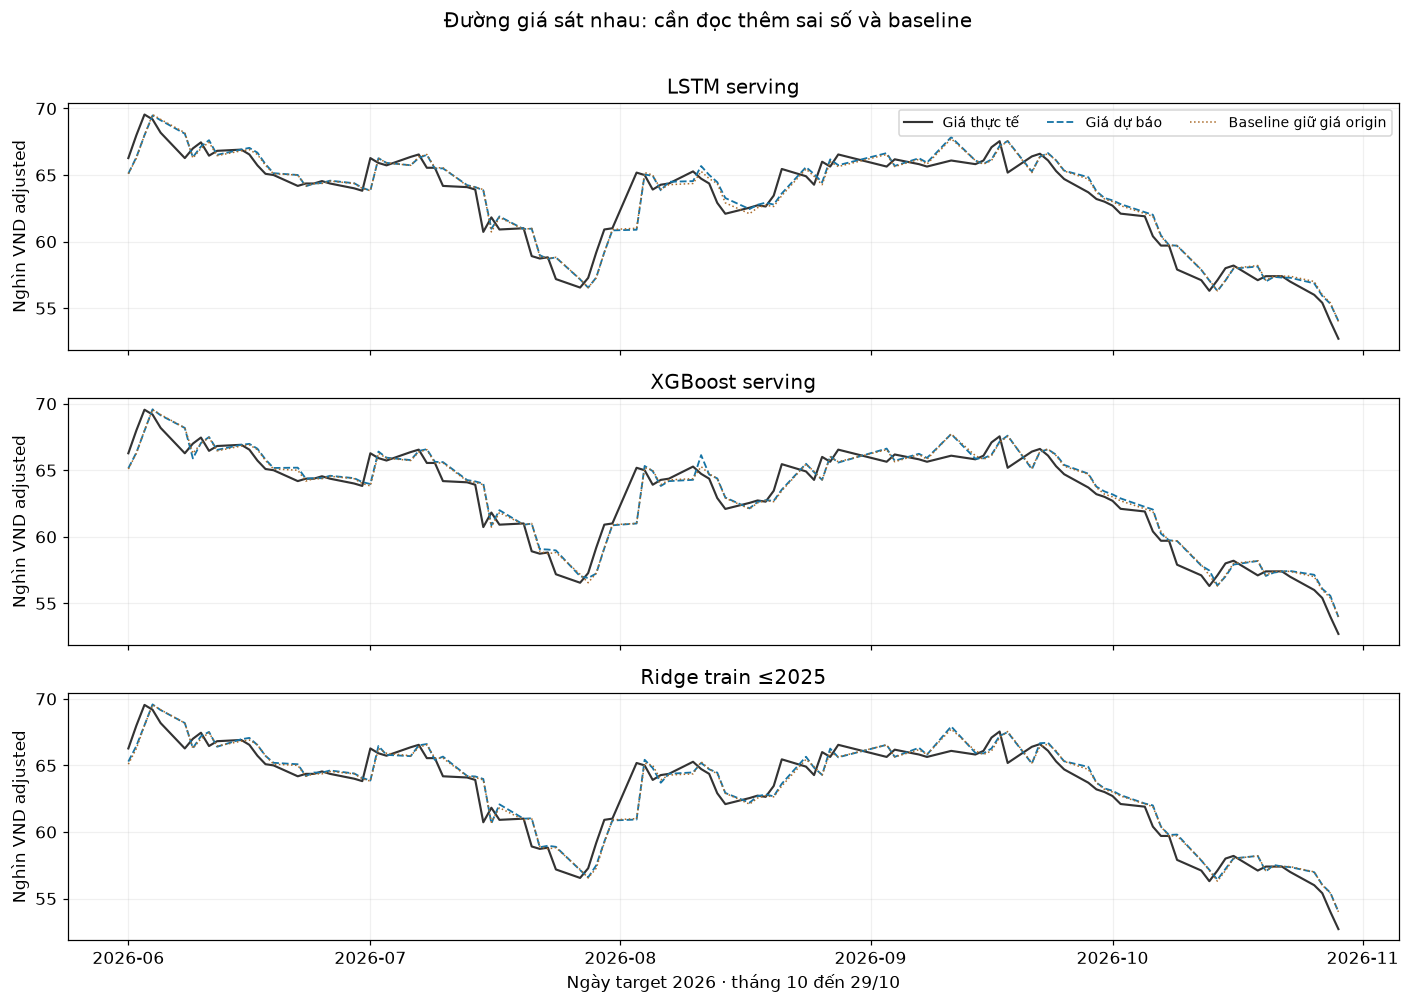

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True, sharey=True)
for ax, model in zip(axes, PRICE_MODELS):
    g = predictions[predictions.strategy.eq(model)].sort_values('Date')
    ax.plot(g.Target_Date_1d, g.actual_close_adjusted/1000, color='#333333', lw=1.4, label='Giá thực tế')
    ax.plot(g.Target_Date_1d, g.predicted_close_adjusted/1000, color='#1674a5', ls='--', lw=1.2, label='Giá dự báo')
    ax.plot(g.Target_Date_1d, g.origin_close_adjusted/1000, color='#aa6a28', ls=':', lw=1, label='Baseline giữ giá origin')
    ax.set_title(LABELS[model]); ax.set_ylabel('Nghìn VND adjusted')
axes[0].legend(ncol=3, fontsize=9)
axes[-1].set_xlabel('Ngày target 2026 · tháng 10 đến 29/10')
fig.suptitle('Đường giá sát nhau: cần đọc thêm sai số và baseline', y=1.01)
show('01_predicted_price')

### Mức tăng/giảm mới cho thấy model có bắt được chuyển động không
Đổi log-return sang simple return: `100 × (exp(return) − 1)`. Cùng thang trục y để không làm đường dự báo trông nhạy hơn bằng cách đổi scale. Đoán đúng độ lớn nhưng sai dấu vẫn là sai hướng.

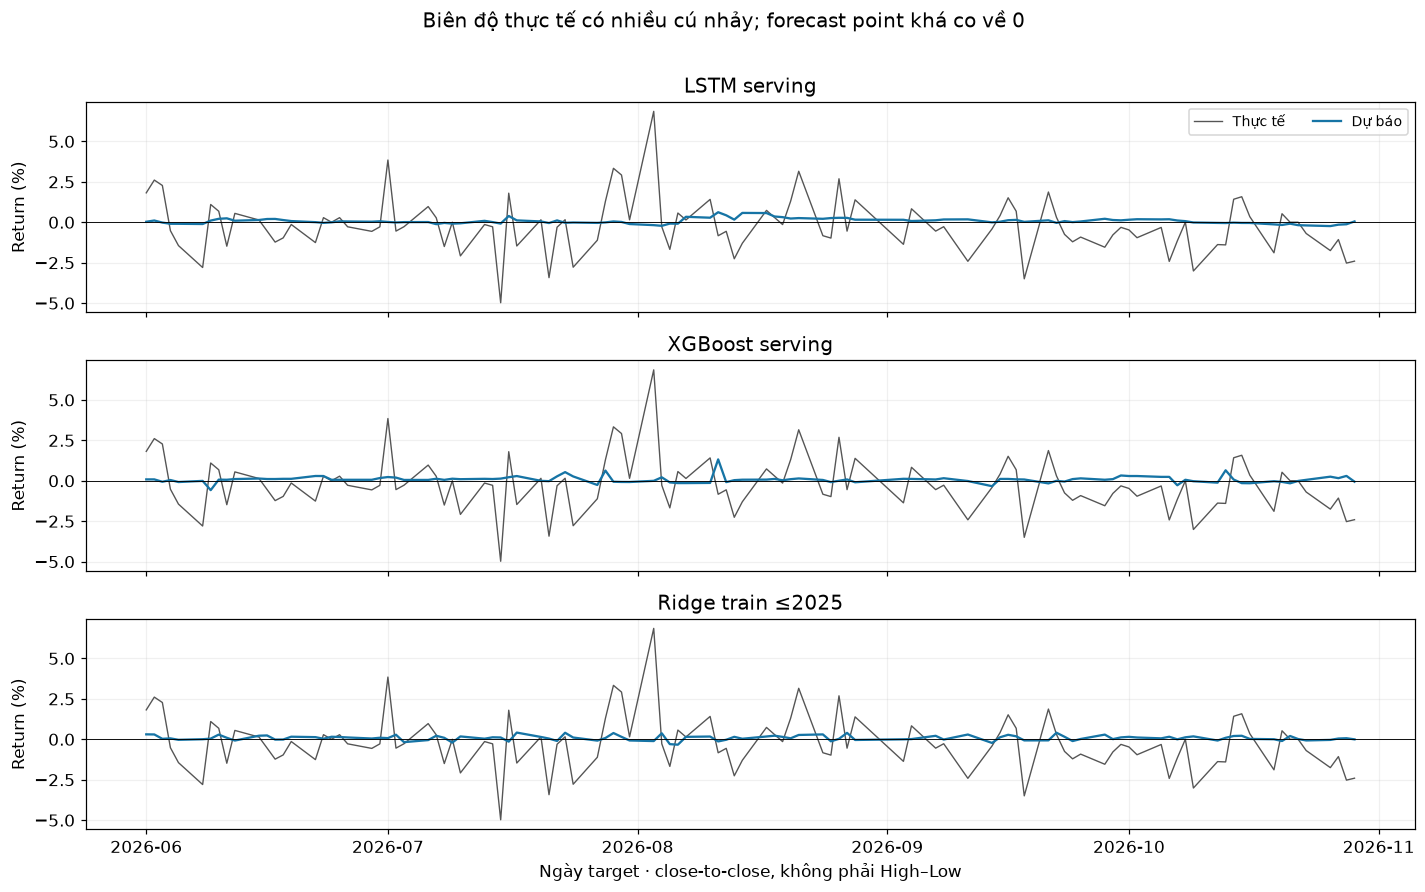

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True, sharey=True)
for ax, model in zip(axes, PRICE_MODELS):
    g = predictions[predictions.strategy.eq(model)].sort_values('Date')
    ax.plot(g.Target_Date_1d, g.actual_return_pct, color='#555555', lw=.9, label='Thực tế')
    ax.plot(g.Target_Date_1d, g.predicted_return_pct, color='#1674a5', lw=1.5, label='Dự báo')
    ax.axhline(0, color='black', lw=.6); ax.set_ylabel('Return (%)'); ax.set_title(LABELS[model])
axes[0].legend(ncol=2, fontsize=9); axes[-1].set_xlabel('Ngày target · close-to-close, không phải High–Low')
fig.suptitle('Biên độ thực tế có nhiều cú nhảy; forecast point khá co về 0', y=1.01)
show('02_actual_predicted_returns')

## 4. Phóng to một tháng / một model
Thay hai tham số đầu notebook để đọc tháng khác. Phía trên là giá; phía dưới là return theo phiên. Bảng theo ngày cho thấy chính xác thực tế tăng/giảm bao nhiêu, model đoán gì và sai bao nhiêu. Không dùng metric 104 phiên làm metric riêng của tháng đang chọn.

**LSTM serving · 2026-10 · 21 phiên**. Nhóm: Cố định · chỉ học nhãn trước 2026

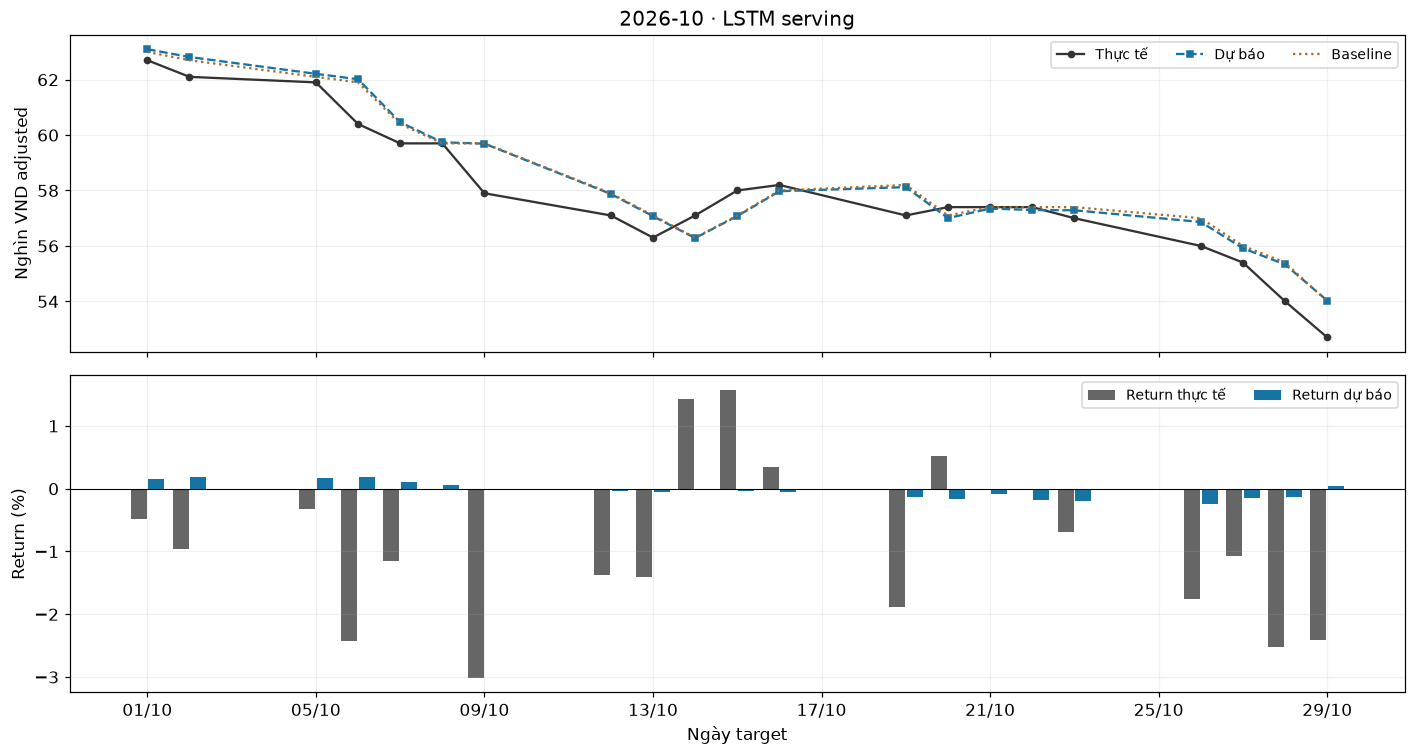

,N,RMSE log-return,MAE giá VND adj.,Hit (%),Balanced (%),MSE skill (%)
0,21,0.015,716.286,44.444,28.571,0.329


In [7]:
detail = predictions[(predictions.strategy==DETAIL_MODEL)&(predictions.target_month==DETAIL_MONTH)].sort_values('Date').copy()
detail_metrics = monthly[(monthly.strategy==DETAIL_MODEL)&(monthly.target_month==DETAIL_MONTH)].iloc[0]
display(Markdown(f"**{LABELS.get(DETAIL_MODEL, DETAIL_MODEL)} · {DETAIL_MONTH} · {len(detail)} phiên**. Nhóm: {GROUP_LABELS[summary.loc[DETAIL_MODEL,'mode']]}"))
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(detail.Target_Date_1d, detail.actual_close_adjusted/1000, 'o-', color='#333333', ms=4, label='Thực tế')
axes[0].plot(detail.Target_Date_1d, detail.predicted_close_adjusted/1000, 's--', color='#1674a5', ms=4, label='Dự báo')
axes[0].plot(detail.Target_Date_1d, detail.origin_close_adjusted/1000, ':', color='#aa6a28', label='Baseline')
axes[0].set_ylabel('Nghìn VND adjusted'); axes[0].legend(ncol=3, fontsize=9)
axes[0].set_title(f'{DETAIL_MONTH} · {LABELS.get(DETAIL_MODEL, DETAIL_MODEL)}')
axes[1].bar(detail.Target_Date_1d-pd.Timedelta(hours=5), detail.actual_return_pct, width=.38, color='#666666', label='Return thực tế')
axes[1].bar(detail.Target_Date_1d+pd.Timedelta(hours=5), detail.predicted_return_pct, width=.38, color='#1674a5', label='Return dự báo')
axes[1].axhline(0, color='black', lw=.7); axes[1].set_ylabel('Return (%)'); axes[1].legend(ncol=2, fontsize=9)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d/%m')); axes[1].set_xlabel('Ngày target')
show('03_month_zoom')
display(readable(pd.DataFrame([{'N':len(detail),'RMSE log-return':detail_metrics.rmse,
    'MAE giá VND adj.':detail_metrics.price_mae_adjusted_vnd,'Hit (%)':detail_metrics.hit_rate_pct,
    'Balanced (%)':detail_metrics.balanced_accuracy_pct,'MSE skill (%)':100*detail_metrics.mse_skill_vs_zero}])))

In [8]:
daily = detail[['Date','Target_Date_1d','actual_close_adjusted','predicted_close_adjusted',
                'actual_return_pct','predicted_return_pct','price_error_pct']].copy()
daily['Sai số giá tuyệt đối (VND)'] = abs(daily.predicted_close_adjusted-daily.actual_close_adjusted)
y, q = detail.actual_log_return.to_numpy(), detail.predicted_log_return.to_numpy()
daily['Đúng hướng'] = ['N/A: thực tế 0' if a==0 else ('Abstain: dự báo 0' if b==0 else ('Đúng' if np.sign(a)==np.sign(b) else 'Sai')) for a,b in zip(y,q)]
daily.Date = daily.Date.dt.strftime('%d/%m'); daily.Target_Date_1d = daily.Target_Date_1d.dt.strftime('%d/%m')
daily = daily.rename(columns={'Date':'Origin','Target_Date_1d':'Target','actual_close_adjusted':'Giá thật (VND adj.)',
    'predicted_close_adjusted':'Giá đoán (VND adj.)','actual_return_pct':'Return thật (%)',
    'predicted_return_pct':'Return đoán (%)','price_error_pct':'Sai số giá có dấu (%)'})
display(daily.style.format(precision=2, na_rep='—').hide(axis='index'))

Origin,Target,Giá thật (VND adj.),Giá đoán (VND adj.),Return thật (%),Return đoán (%),Sai số giá có dấu (%),Sai số giá tuyệt đối (VND),Đúng hướng
30/09,01/10,62700.00,63097.19,-0.48,0.15,0.63,397.19,Sai
01/10,02/10,62100.00,62816.26,-0.96,0.19,1.15,716.26,Sai
02/10,05/10,61900.00,62208.89,-0.32,0.18,0.50,308.89,Sai
05/10,06/10,60400.00,62014.14,-2.42,0.18,2.67,1614.14,Sai
06/10,07/10,59700.00,60464.69,-1.16,0.11,1.28,764.69,Sai
07/10,08/10,59700.00,59739.66,0.00,0.07,0.07,39.66,N/A: thực tế 0
08/10,09/10,57900.00,59689.78,-3.02,-0.02,3.09,1789.78,Đúng
09/10,12/10,57100.00,57875.37,-1.38,-0.04,1.36,775.37,Đúng
12/10,13/10,56300.00,57071.75,-1.40,-0.05,1.37,771.75,Đúng
13/10,14/10,57100.00,56284.92,1.42,-0.03,-1.43,815.08,Sai


## 5. So sánh toàn bộ giai đoạn: sai số và bất định
RMSE/MAE càng thấp càng tốt. **MSE skill = 1 − MSE(model)/MSE(Zero)**; dương là tốt hơn baseline trên cùng ngày. Giá trị rất nhỏ quanh 0 không tự chứng minh lợi thế. Hai panel tách mô hình cố định với phương án cập nhật bằng nhãn đã chín. Khoảng 95% dưới đây là block-bootstrap mô tả trên 104 origin (block 10, 2.000 resamples, seed 20261030), không phải khoảng dự báo giá và không xử lý hết việc thử nhiều phương án.

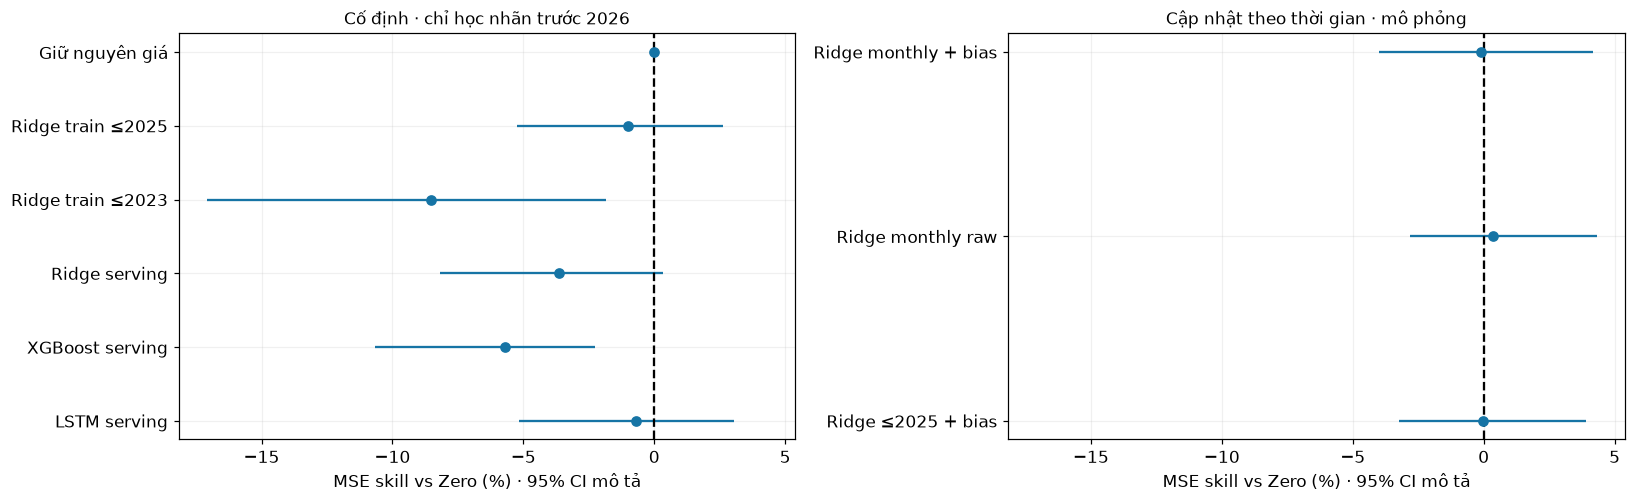

,N,RMSE return,MAE giá VND adj.,MAPE (%),Hit (%),Balanced (%),MSE skill (%)
LSTM serving,104,0.0168315,786.38,1.253,47.47,50.83,-0.680
XGBoost serving,104,0.0172463,810.83,1.293,38.38,41.99,-5.704
Ridge serving,104,0.0170783,787.96,1.257,45.45,49.17,-3.654
Ridge train ≤2023,104,0.0174742,816.20,1.304,40.40,48.59,-8.516
Ridge train ≤2025,104,0.0168589,781.62,1.246,50.51,55.13,-1.009
Ridge ≤2025 + bias,104,0.0167760,767.28,1.221,62.63,57.95,-0.017
Ridge monthly raw,104,0.0167461,771.17,1.229,55.56,57.05,+0.339
Ridge monthly + bias,104,0.0167832,767.21,1.221,57.58,53.78,-0.103
Giữ nguyên giá,104,0.0167746,773.51,1.233,—,—,+0.000


RMSE gộp tính trực tiếp trên 104 forecast; không lấy trung bình RMSE từng tháng. Các CI gần baseline vẫn chứa 0: chưa có lợi thế chắc chắn.

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.7), sharex=True)
for ax, mode in zip(axes, GROUP_LABELS):
    group = summary.loc[FOCUS]; group = group[group['mode']==mode]
    positions = np.arange(len(group))
    ax.hlines(positions, 100*group.mse_skill_ci_low, 100*group.mse_skill_ci_high, color='#1674a5')
    ax.scatter(100*group.mse_skill_vs_zero, positions, color='#1674a5', zorder=3)
    ax.axvline(0, color='black', ls='--'); ax.set_yticks(positions, [LABELS[x] for x in group.index])
    ax.set_title(GROUP_LABELS[mode], fontsize=11); ax.set_xlabel('MSE skill vs Zero (%) · 95% CI mô tả')
show('04_skill_uncertainty')
selected = summary.loc[FOCUS, ['n','rmse','price_mae_adjusted_vnd','price_mape_pct','hit_rate_pct','balanced_accuracy_pct','mse_skill_vs_zero']].copy()
selected['mse_skill_vs_zero'] *= 100; selected.index = [LABELS[x] for x in selected.index]
selected = selected.rename(columns={'n':'N','rmse':'RMSE return','price_mae_adjusted_vnd':'MAE giá VND adj.',
    'price_mape_pct':'MAPE (%)','hit_rate_pct':'Hit (%)','balanced_accuracy_pct':'Balanced (%)','mse_skill_vs_zero':'MSE skill (%)'})
display(selected.style.format({'N':'{:.0f}','RMSE return':'{:.7f}','MAE giá VND adj.':'{:.2f}',
    'MAPE (%)':'{:.3f}','Hit (%)':'{:.2f}','Balanced (%)':'{:.2f}','MSE skill (%)':'{:+.3f}'}, na_rep='—'))
display(Markdown('RMSE gộp tính trực tiếp trên 104 forecast; không lấy trung bình RMSE từng tháng. Các CI gần baseline vẫn chứa 0: chưa có lợi thế chắc chắn.'))

## 6. Model có ổn định qua từng tháng không?
Màu xanh = tốt hơn baseline, đỏ = kém hơn. Mỗi tháng dùng cùng ngày giữa các model, nhưng số phiên giữa các tháng khác nhau (18–23). Không dùng CI của toàn giai đoạn cho từng tháng. Tháng 10 chỉ tới 29/10.

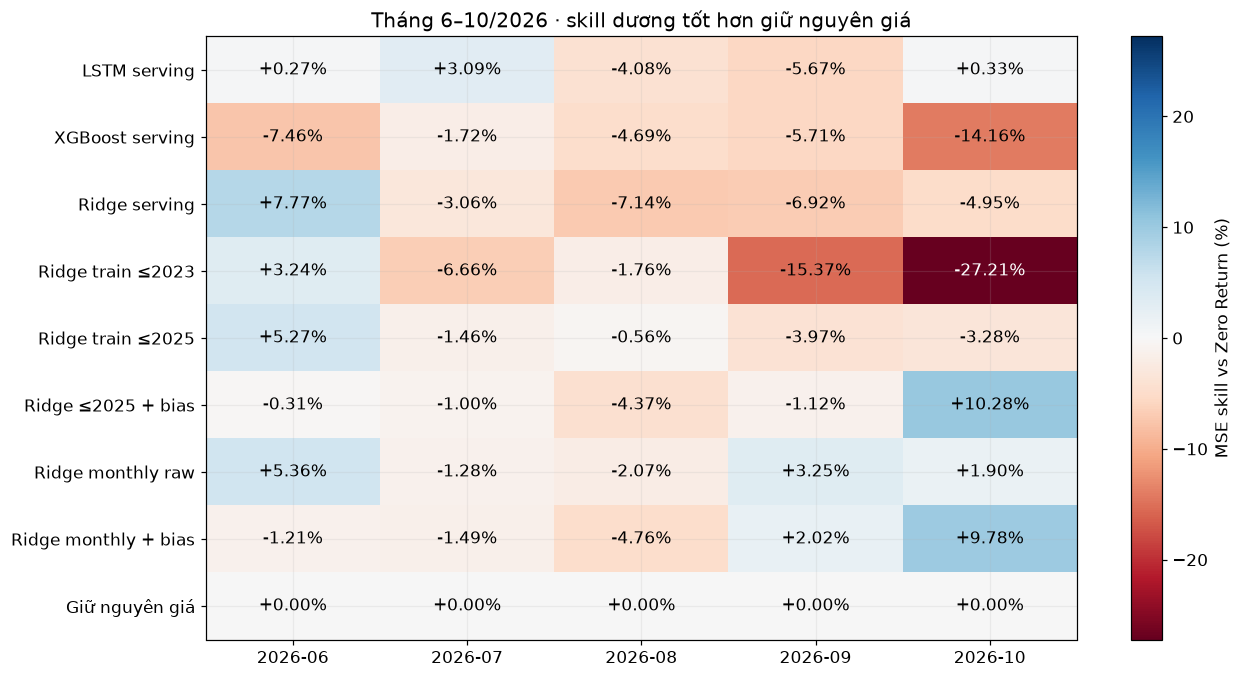

strategy,LSTM serving,XGBoost serving,Giữ nguyên giá,Ridge monthly raw,Ridge train ≤2025
target_month,,,,,
2026-06,0.0125245,0.0130005,0.0125413,0.0122005,0.0122066
2026-07,0.0201215,0.0206142,0.0204395,0.0205694,0.0205885
2026-08,0.0204078,0.0204676,0.0200038,0.0202097,0.0200595
2026-09,0.0141786,0.0141815,0.0137933,0.0135676,0.0140641
2026-10,0.0150425,0.0160989,0.0150672,0.0149235,0.0153122


Monthly Ridge raw tốt hơn Zero ở tháng 6, 9, 10; kém ở 7, 8. LSTM cũng đổi dấu lợi thế giữa các tháng. Không có phương án thắng đều mọi tháng trong bảng.

In [10]:
grid = monthly[monthly.strategy.isin(FOCUS)].pivot(index='strategy',columns='target_month',values='mse_skill_vs_zero').reindex(FOCUS)*100
limit = max(1., float(abs(grid).max().max()))
fig, ax = plt.subplots(figsize=(12, 6.3))
image = ax.imshow(grid, cmap='RdBu', vmin=-limit, vmax=limit, aspect='auto')
ax.set_yticks(range(len(grid)), [LABELS[x] for x in grid.index]); ax.set_xticks(range(len(grid.columns)), grid.columns)
for i in range(len(grid)):
    for j in range(len(grid.columns)):
        value = grid.iloc[i,j]
        ax.text(j,i,f'{value:+.2f}%',ha='center',va='center',color='white' if abs(value)>.6*limit else 'black')
fig.colorbar(image, ax=ax, label='MSE skill vs Zero Return (%)')
ax.set_title('Tháng 6–10/2026 · skill dương tốt hơn giữ nguyên giá')
show('05_monthly_skill')
monthly_rmse = monthly[monthly.strategy.isin(PRICE_MODELS+['monthly_refit_native','Zero-Return'])].pivot(index='target_month',columns='strategy',values='rmse')
monthly_rmse = monthly_rmse.rename(columns=LABELS)
display(monthly_rmse.style.format('{:.7f}'))
display(Markdown('Monthly Ridge raw tốt hơn Zero ở tháng 6, 9, 10; kém ở 7, 8. LSTM cũng đổi dấu lợi thế giữa các tháng. Không có phương án thắng đều mọi tháng trong bảng.'))

## 7. Đúng hướng và tỷ lệ dự báo gần giá thật
Hit chỉ tính **99 nhãn khác 0**, giữ 5 nhãn bằng 0 trong RMSE/MAE và ngưỡng sai số giá. Đoán giảm luôn đạt 60,61% Hit nhưng balanced chỉ 50%; đây là tỷ lệ lớp quan sát, không phải chiến lược được chọn sau khi biết kết quả. Balanced accuracy = trung bình recall tăng và giảm. Zero Return là abstention nên Hit/Balanced để trống.

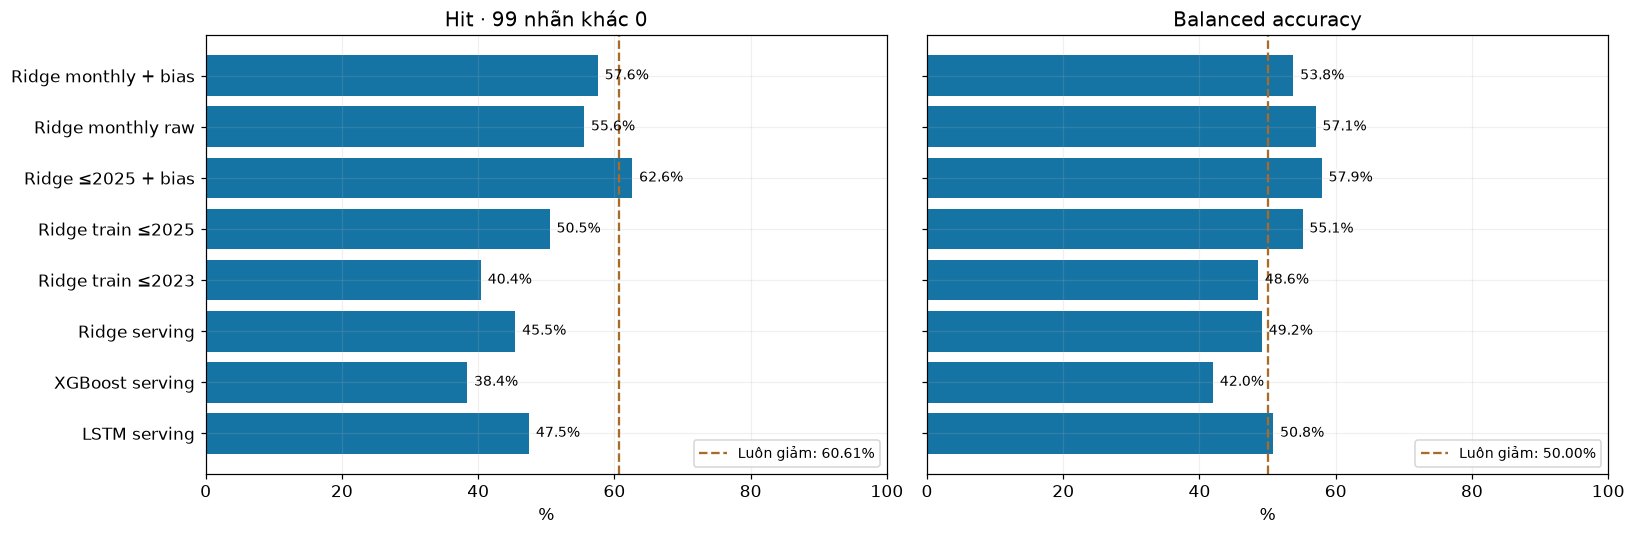

,Bắt đúng ngày tăng (%),Bắt đúng ngày giảm (%)
strategy,,
LSTM serving,66.667,35.000
XGBoost serving,58.974,25.000
Ridge serving,66.667,31.667
Ridge train ≤2023,87.179,10.000
Ridge train ≤2025,76.923,33.333
Ridge ≤2025 + bias,35.897,80.000
Ridge monthly raw,64.103,50.000
Ridge monthly + bias,35.897,71.667


In [11]:
direction_models = [x for x in FOCUS if x!='Zero-Return']
direction = summary.loc[direction_models]
always_down_hit = 100*(baseline.actual_log_return<0).sum()/(baseline.actual_log_return!=0).sum()
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, metric, title, reference in [(axes[0],'hit_rate_pct','Hit · 99 nhãn khác 0',always_down_hit),
                                      (axes[1],'balanced_accuracy_pct','Balanced accuracy',50.)]:
    values = direction[metric].to_numpy(); ax.barh(range(len(direction)), values, color='#1674a5')
    ax.axvline(reference, color='#aa6a28', ls='--', label=f'Luôn giảm: {reference:.2f}%')
    ax.set_yticks(range(len(direction)), [LABELS[x] for x in direction.index]); ax.set_xlim(0,100)
    for i,value in enumerate(values): ax.text(value+1,i,f'{value:.1f}%',va='center',fontsize=9)
    ax.set_xlabel('%'); ax.set_title(title); ax.legend(fontsize=9, loc='lower right')
show('06_direction')
recalls = direction[['up_recall_pct','down_recall_pct']].rename(index=LABELS,columns={'up_recall_pct':'Bắt đúng ngày tăng (%)','down_recall_pct':'Bắt đúng ngày giảm (%)'})
display(readable(recalls))

### “Sai số trong ±1% / ±2%” nghĩa là gì?
Tính `abs(predicted_price / actual_price − 1)` và đếm tỷ lệ không vượt ngưỡng 1% hoặc 2%. Mẫu số là cả 104 phiên. Đây là **tỷ lệ đạt một ngưỡng sai số đã định nghĩa**, không phải xác suất forecast phiên tới đúng; MAPE 1,25% cũng không có nghĩa accuracy 98,75%. Baseline cũng phải được chấm bằng cùng ngưỡng.

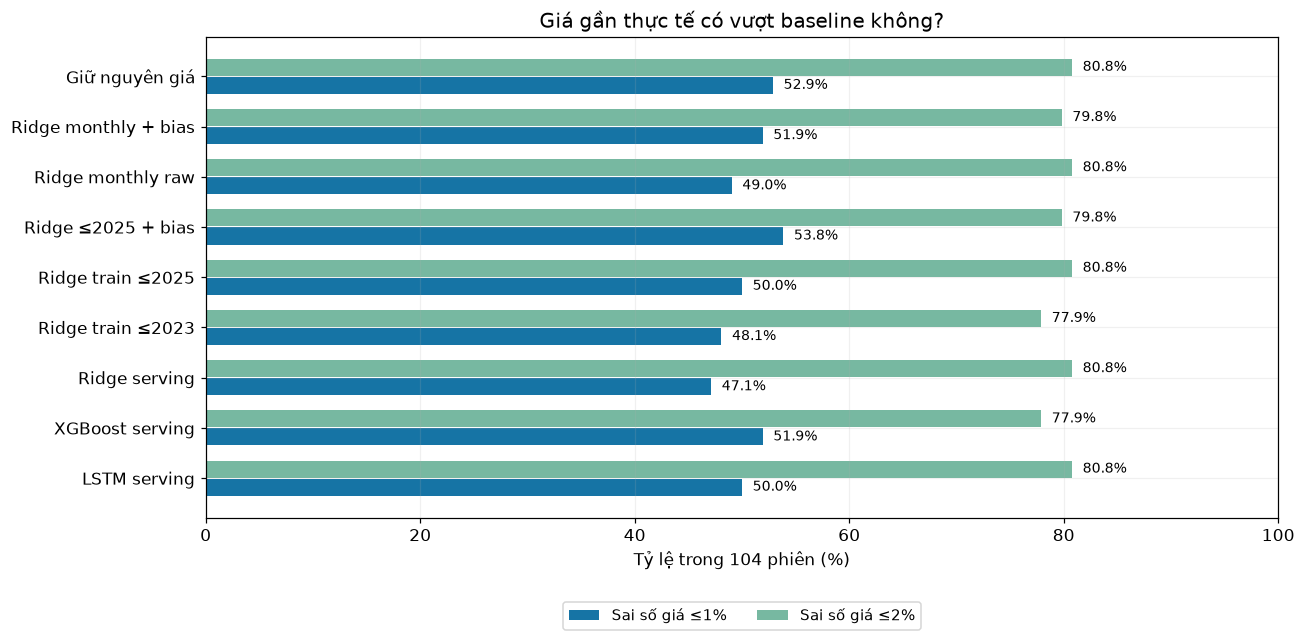

LSTM và baseline đều có 84/104 phiên sai số ≤2% (80,77%). Không thể dùng riêng tỷ lệ này để kết luận ML có ích.

In [12]:
thresholds = summary.loc[FOCUS]
positions = np.arange(len(thresholds))
fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(positions-.18, thresholds.price_error_le_1pct_pct, height=.34, color='#1674a5', label='Sai số giá ≤1%')
ax.barh(positions+.18, thresholds.price_error_le_2pct_pct, height=.34, color='#77b8a1', label='Sai số giá ≤2%')
ax.set_yticks(positions, [LABELS[x] for x in thresholds.index]); ax.set_xlim(0,100)
for i,(_,r) in enumerate(thresholds.iterrows()):
    ax.text(r.price_error_le_1pct_pct+1,i-.18,f'{r.price_error_le_1pct_pct:.1f}%',va='center',fontsize=9)
    ax.text(r.price_error_le_2pct_pct+1,i+.18,f'{r.price_error_le_2pct_pct:.1f}%',va='center',fontsize=9)
ax.set_xlabel('Tỷ lệ trong 104 phiên (%)'); ax.set_title('Giá gần thực tế có vượt baseline không?')
ax.legend(loc='upper center', bbox_to_anchor=(.5,-.16), ncol=2, fontsize=10)
show('07_price_thresholds')
display(Markdown('LSTM và baseline đều có 84/104 phiên sai số ≤2% (80,77%). Không thể dùng riêng tỷ lệ này để kết luận ML có ích.'))

## 8. Biên độ dự báo có quá nhỏ không?
Std của simple return là **độ biến động của chuỗi**, không phải sai số hoặc độ chắc chắn. Forecast point có thể là mean có điều kiện, vốn biến động ít hơn actual có nhiễu. Không tự nhân độ lớn forecast cho giống đường thực tế. Đọc cùng sai hướng, return MAE và baseline.

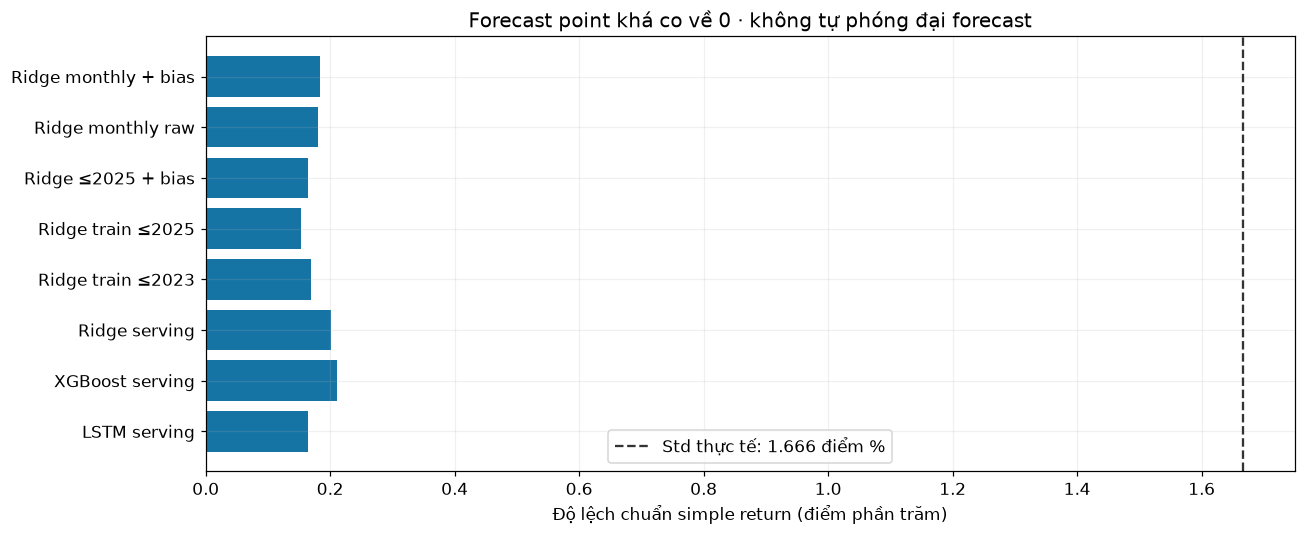

,Std dự báo (điểm %),Std thật (điểm %),MAE signed return (điểm %),MAE độ lớn |return| (điểm %)
strategy,,,,
LSTM serving,0.164,1.666,1.250,1.115
XGBoost serving,0.211,1.666,1.290,1.106
Ridge serving,0.202,1.666,1.254,1.093
Ridge train ≤2023,0.169,1.666,1.300,1.051
Ridge train ≤2025,0.153,1.666,1.243,1.117
Ridge ≤2025 + bias,0.164,1.666,1.220,1.105
Ridge monthly raw,0.180,1.666,1.227,1.119
Ridge monthly + bias,0.184,1.666,1.220,1.101


MAE độ lớn bỏ dấu: dự báo +2% và thực tế −2% có độ lớn đúng nhưng hướng sai. Chỉ số này không thay MAE signed return hoặc Hit.

In [13]:
amplitude_models = [x for x in FOCUS if x!='Zero-Return']
amplitude = summary.loc[amplitude_models]
actual_std = float(summary.loc['Zero-Return','actual_return_std_pp'])
fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(range(len(amplitude)), amplitude.predicted_return_std_pp, color='#1674a5')
ax.axvline(actual_std, color='#333333', ls='--', label=f'Std thực tế: {actual_std:.3f} điểm %')
ax.set_yticks(range(len(amplitude)), [LABELS[x] for x in amplitude.index]); ax.set_xlim(left=0)
ax.set_xlabel('Độ lệch chuẩn simple return (điểm phần trăm)'); ax.set_title('Forecast point khá co về 0 · không tự phóng đại forecast'); ax.legend()
show('08_return_amplitude')
amplitude_table = amplitude[['predicted_return_std_pp','actual_return_std_pp','return_mae_pp','magnitude_mae_pp']].rename(index=LABELS,
    columns={'predicted_return_std_pp':'Std dự báo (điểm %)','actual_return_std_pp':'Std thật (điểm %)',
             'return_mae_pp':'MAE signed return (điểm %)','magnitude_mae_pp':'MAE độ lớn |return| (điểm %)'})
display(readable(amplitude_table))
display(Markdown('MAE độ lớn bỏ dấu: dự báo +2% và thực tế −2% có độ lớn đúng nhưng hướng sai. Chỉ số này không thay MAE signed return hoặc Hit.'))

## Kết luận và nguồn
1. So trên cùng giai đoạn cho thấy model nào sai ở đâu, nhưng chưa chứng minh lợi thế ngoài giai đoạn đó. LSTM khá gần baseline; monthly Ridge chỉ nhỉnh hơn ít, CI còn chứa 0.
2. Bias có thể tăng Hit/giảm MAE mà không cải thiện RMSE. Không chọn model bằng một metric hoặc một tháng tốt.
3. Forecast return khá nhỏ so actual, bỏ lỡ nhiều cú nhảy; chưa đủ cơ sở phóng đại biên độ. Cần kiểm chứng bằng các phiên mới đã ghi forecast trước khi có nhãn.
4. Muốn dự báo cả tháng từ đầu tháng hoặc High–Low cần target/horizon/baseline khác. Không dùng điểm one-step ở đây làm đại diện.

**Nguồn đã lưu:** `reports/period_comparison/20261030T024048531444Z/COMPARISON.md`, `analysis.py`, `scope.json`, `verification.json`, `predictions.csv.gz`, `summary.csv`, `monthly_metrics.csv`.

**Study gốc:** `reports/evaluation_2026/20261030T014012158951Z/` và `reports/recency_bias/20261030T022440928507Z/`. Notebook chỉ đọc các kết quả này, không gọi source provider, train/reload weights hoặc thay serving/API/Streamlit. Không commit/push.

Các biểu đồ dùng Matplotlib có code chỉnh sửa ngay trong cell và output PNG tự chứa trong notebook. Phần phóng to dùng tham số ở đầu; không cần live kernel để xem kết quả mặc định đã lưu.